# Step 1: Load the data and remove Toluene

**What this notebook does**
1. Reads the 10 raw batch files (`batch1.dat` ... `batch10.dat`) into one table.
2. Runs automatic checks on the raw data.
3. Removes all Toluene (label 6) samples, as instructed by the teacher.
4. Runs the same checks again on the cleaned data.

The raw files are never changed; Toluene is removed in code only.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from src import data_loader as dl

pd.set_option("display.width", 140)

## 1. Load all 10 batches

In [2]:
raw = dl.load_all()
print("Shape (rows, columns):", raw.shape)
raw[["batch", "label", "gas", "f1", "f2", "f3", "f128"]].head()

Shape (rows, columns): (13910, 131)


,batch,label,gas,f1,f2,f3,f128
0,1,1,Ethanol,15596.1621,1.868245,2.371604,-2.654529
1,1,1,Ethanol,26402.0704,2.532401,5.411209,-1.749225
2,1,1,Ethanol,42103.5820,3.454189,8.198175,-2.348370
3,1,1,Ethanol,42825.9883,3.451192,12.113940,-2.488957
4,1,1,Ethanol,58151.1757,4.194839,11.455096,-4.088756


Each row is one gas measurement. The columns are the batch number (1-10, in time order), the gas
label and name, and 128 numeric features (16 sensors x 8 features each).

## 2. Checks on the raw data (6 gases)

In [3]:
def show_checks(results):
    table = pd.DataFrame(
        [(name, "PASS" if ok else "FAIL", detail) for name, (ok, detail) in results.items()],
        columns=["check", "result", "detail"])
    return table

raw_checks = dl.check_dataset(raw, dl.EXPECTED_BEFORE, allowed_labels=range(1, 7))
show_checks(raw_checks)

,check,result,detail
0,128 feature columns,PASS,128 columns
1,no missing values (NaN),PASS,0 NaN
2,no infinite values,PASS,all finite
3,total row count,PASS,13910 rows (expected 13910)
4,per-batch row counts,PASS,"got {1: 445, 2: 1244, 3: 1586, 4: 161, 5: 197,..."
5,labels are allowed,PASS,"labels present: [np.int64(1), np.int64(2), np...."


## 3. Where is Toluene?

In [4]:
toluene_per_batch = raw[raw["label"] == 6].groupby("batch").size().reindex(range(1, 11), fill_value=0)
before = dl.counts_per_batch(raw)
clean = dl.remove_toluene(raw)
after = dl.counts_per_batch(clean)

summary = pd.DataFrame({"before": before, "toluene_removed": toluene_per_batch, "after": after})
summary.loc["Total"] = summary.sum()
summary

,before,toluene_removed,after
batch,,,
1,445,74,371
2,1244,5,1239
3,1586,0,1586
4,161,0,161
5,197,0,197
6,2300,467,1833
7,3613,568,3045
8,294,18,276
9,470,101,369


Toluene is missing from batches 3, 4 and 5 and has only 5 samples in batch 2, which is why the
class set would otherwise change from batch to batch.

## 4. Checks on the cleaned data (5 gases)

In [5]:
clean_checks = dl.check_dataset(clean, dl.EXPECTED_AFTER, allowed_labels=range(1, 6))
show_checks(clean_checks)

,check,result,detail
0,128 feature columns,PASS,128 columns
1,no missing values (NaN),PASS,0 NaN
2,no infinite values,PASS,all finite
3,total row count,PASS,12077 rows (expected 12077)
4,per-batch row counts,PASS,"got {1: 371, 2: 1239, 3: 1586, 4: 161, 5: 197,..."
5,labels are allowed,PASS,"labels present: [np.int64(1), np.int64(2), np...."


In [6]:
assert all(ok for ok, _ in raw_checks.values()), "raw data check failed"
assert all(ok for ok, _ in clean_checks.values()), "clean data check failed"
print("All checks passed.")
print("Rows before:", len(raw), "| rows after:", len(clean))

All checks passed.
Rows before: 13910 | rows after: 12077


## 5. Samples per gas in each batch (after removing Toluene)

In [7]:
gas_counts = clean.groupby(["batch", "gas"]).size().unstack(fill_value=0)
gas_counts = gas_counts[["Ethanol", "Ethylene", "Ammonia", "Acetaldehyde", "Acetone"]]
gas_counts

gas,Ethanol,Ethylene,Ammonia,Acetaldehyde,Acetone
batch,,,,,
1,90,98,83,30,70
2,164,334,100,109,532
3,365,490,216,240,275
4,64,43,12,30,12
5,28,40,20,46,63
6,514,574,110,29,606
7,649,662,360,744,630
8,30,30,40,33,143
9,61,55,100,75,78


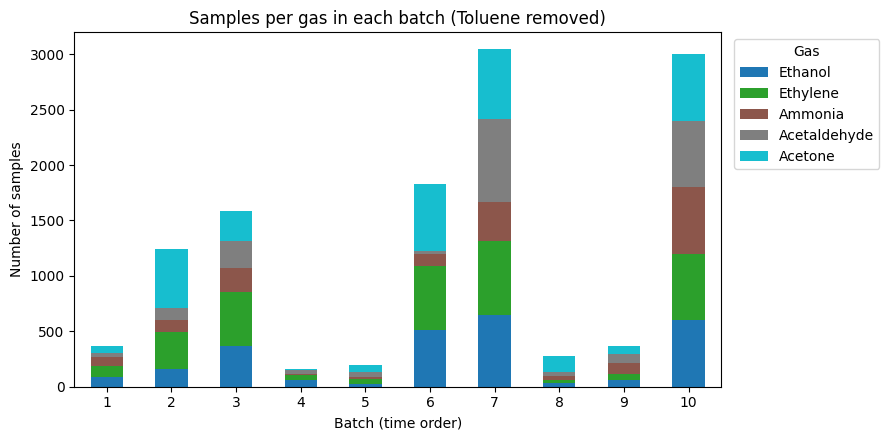

In [8]:
ax = gas_counts.plot(kind="bar", stacked=True, figsize=(9, 4.5), colormap="tab10")
ax.set_xlabel("Batch (time order)")
ax.set_ylabel("Number of samples")
ax.set_title("Samples per gas in each batch (Toluene removed)")
ax.legend(title="Gas", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../results/step1_samples_per_batch.png", dpi=150)
plt.show()

**What to notice:** batches 7 and 10 are the largest; batches 4 and 5 are tiny, so results on them will be
noisy. Batch 10 is perfectly balanced (600 per gas before removal, 3,000 after).

In [9]:
summary.to_csv("../results/step1_counts.csv")
gas_counts.to_csv("../results/step1_gas_counts_per_batch.csv")
print("Saved results to ../results/")

Saved results to ../results/
